# Credit Risk Analysis


This notebook explores customer characteristics associated with serious delinquency using the Give Me Some Credit dataset.


The analysis covers data loading, initial exploration, missing-value treatment, exploratory analysis and risk segmentation.

In [2]:
%pip install pandas numpy matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("cs-training.csv")

Note: you may need to restart the kernel to use updated packages.


## 1. Load and inspect the dataset


Display the imported dataset to check that it has loaded and to inspect its contents.

In [3]:
display(df)

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
149995,149996,0,0.040674,74,0,0.225131,2100.0,4,0,1,0,0.0
149996,149997,0,0.299745,44,0,0.716562,5584.0,4,0,1,0,2.0
149997,149998,0,0.246044,58,0,3870.000000,NaN,18,0,1,0,0.0
149998,149999,0,0.000000,30,0,0.000000,5716.0,4,0,0,0,0.0


## 2. Understand the target variable


Count the number of customers with and without serious delinquency (`SeriousDlqin2yrs`).

In [4]:
df["SeriousDlqin2yrs"].value_counts()

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

Calculate the percentage split between customers with and without serious delinquency.

In [5]:
df["SeriousDlqin2yrs"].value_counts(normalize=True) * 100

SeriousDlqin2yrs
0    93.316
1     6.684
Name: proportion, dtype: float64

Preview the first few rows to inspect the columns and values.

In [6]:
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 3. Check data quality


Identify missing values in each column before deciding how to handle them.

In [7]:
df.isna().sum()

Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

## 4. Handle missing values


Fill missing monthly income and number of dependants using each column's median.

In [8]:
df["MonthlyIncome"] = df["MonthlyIncome"].fillna(df["MonthlyIncome"].median())

df["NumberOfDependents"] = df["NumberOfDependents"].fillna(df["NumberOfDependents"].median())

## 5. Exploratory data analysis


Compare average customer characteristics between customers with and without serious delinquency. The median is used for monthly income in this summary.

In [9]:
df.groupby("SeriousDlqin2yrs").agg({
    "RevolvingUtilizationOfUnsecuredLines": "mean",
    "age": "mean",
    "DebtRatio": "mean",
    "MonthlyIncome": "median",
    "NumberOfOpenCreditLinesAndLoans": "mean",
    "NumberOfTimes90DaysLate": "mean",
    "NumberOfDependents": "mean"}).T

SeriousDlqin2yrs,0,1
RevolvingUtilizationOfUnsecuredLines,6.168855,4.367282
age,52.751375,45.926591
DebtRatio,357.151168,295.121066
MonthlyIncome,5400.000000,5240.000000
NumberOfOpenCreditLinesAndLoans,8.493620,7.882306
NumberOfTimes90DaysLate,0.135225,2.091362
NumberOfDependents,0.723527,0.931279


Compare median credit utilisation, debt ratio and monthly income between the two target groups to reduce the influence of extreme values.

In [10]:
df.groupby("SeriousDlqin2yrs").agg({
    "RevolvingUtilizationOfUnsecuredLines": "median",
    "DebtRatio": "median",
    "MonthlyIncome": "median"}).T

SeriousDlqin2yrs,0,1
RevolvingUtilizationOfUnsecuredLines,0.133288,0.838853
DebtRatio,0.362659,0.428227
MonthlyIncome,5400.000000,5240.000000


Visualise credit utilisation by delinquency status using boxplots. The y-axis is limited to 0–2 to make the central distribution easier to inspect.

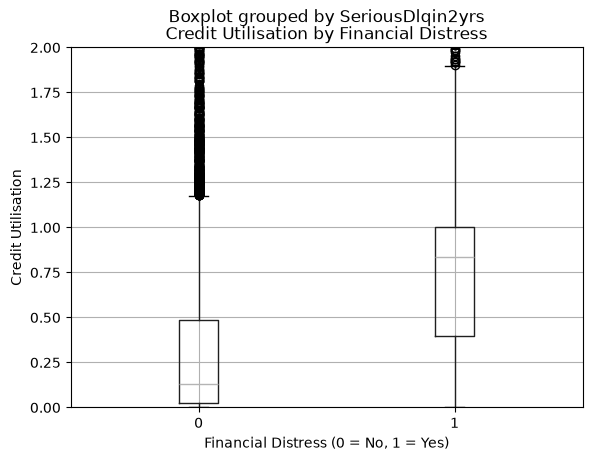

In [11]:
df.boxplot(
    column="RevolvingUtilizationOfUnsecuredLines",
    by="SeriousDlqin2yrs")

plt.title("Credit Utilisation by Financial Distress")
plt.xlabel("Financial Distress (0 = No, 1 = Yes)")
plt.ylabel("Credit Utilisation")
plt.ylim(0, 2)
plt.show()

Measure the percentage of customers in each target group who have at least one recorded 90-day late payment.

In [12]:
df.groupby("SeriousDlqin2yrs")[
    "NumberOfTimes90DaysLate"
].apply(lambda x: (x > 0).mean() * 100)

SeriousDlqin2yrs
0     3.476360
1    34.629962
Name: NumberOfTimes90DaysLate, dtype: float64

## 6. Create risk segments


Group customers into credit-utilisation bands to make the results easier to compare.

In [13]:
df["Utilisation_Band"] = pd.cut(
    df["RevolvingUtilizationOfUnsecuredLines"],
    bins=[-float("inf"), 0.3, 0.6, 0.9, float("inf")],
    labels=["Low (≤30%)", "Moderate (30–60%)",
            "High (60–90%)", "Very High (>90%)"])

Create an indicator for whether a customer has any previous 90-day late payment, then calculate customer counts and distress rates for each combination of utilisation band and payment history.

In [14]:
df["Previous90DayLate"] = (
    df["NumberOfTimes90DaysLate"] > 0)

risk_analysis = df.groupby(
    ["Utilisation_Band", "Previous90DayLate"],
    observed=True)["SeriousDlqin2yrs"].agg(["count", "mean"])

risk_analysis["mean"] *= 100
risk_analysis = risk_analysis.rename(
    columns={"mean": "DistressRate (%)"})
print(risk_analysis)

                                     count  DistressRate (%)
Utilisation_Band  Previous90DayLate                         
Low (≤30%)        False              91336          1.844837
                  True                1546         24.320828
Moderate (30–60%) False              20987          5.503407
                  True                 900         34.111111
High (60–90%)     False              13809         10.406257
                  True                1353         42.867701
Very High (>90%)  False              15530         14.661945
                  True                4539         48.667107


## 7. Export the cleaned dataset


Save the cleaned dataset, including the engineered risk-segmentation columns, as a CSV file for use in SQL and Power BI.

In [15]:
df.to_csv("credit_risk_cleaned_updated.csv", index=False)